# Bassac River Forecasting — Part 3: Model Training & Evaluation

Chronological 80/20 Train/Test split, TimeSeriesSplit validation, model training, and evaluation charts.

In [1]:
# Setup & load modeling table
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

ROOT_DIR = Path('..').resolve()
PROCESSED_DIR = ROOT_DIR / 'data' / 'processed'
MODELS_DIR = ROOT_DIR / 'models'
REPORTS_ML_DIR = ROOT_DIR / 'reports' / 'ml'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_ML_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

FEATURE_COLS = [
    'WL', 'WL_lag1', 'WL_lag2', 'WL_lag3', 'WL_diff',
    'upstream_discharge_lag1', 'upstream_discharge_diff',
    'rain_mm', 'rain_lag1', 'rain_3d'
]
TARGET_COL = 'WL_next'

df = pd.read_csv(PROCESSED_DIR / 'modeling_table.csv', parse_dates=['date']).sort_values('date').reset_index(drop=True)
print('Loaded modeling_table:', df.shape)


Loaded modeling_table: (2285, 13)


In [2]:
# Chronological 80/20 Train / Test split (never shuffle time series)
split_idx = int(len(df) * 0.80)
train_df = df.iloc[:split_idx].reset_index(drop=True)
test_df = df.iloc[split_idx:].reset_index(drop=True)

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_test, y_test = test_df[FEATURE_COLS], test_df[TARGET_COL]

print(f'Train: {len(train_df)} rows ({train_df["date"].min().date()} -> {train_df["date"].max().date()})')
print(f'Test : {len(test_df)} rows ({test_df["date"].min().date()} -> {test_df["date"].max().date()})')


Train: 1828 rows (2020-06-23 -> 2025-08-08)
Test : 457 rows (2025-08-09 -> 2026-11-08)


In [3]:
# Time-series cross-validation on Train set + fit final models
models = {
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
}
tscv = TimeSeriesSplit(n_splits=3)
for name, model in models.items():
    fold_maes = []
    for tr_idx, val_idx in tscv.split(X_train):
        model.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        val_pred = model.predict(X_train.iloc[val_idx])
        fold_maes.append(mean_absolute_error(y_train.iloc[val_idx], val_pred))
    print(f'{name:14s} 3-fold CV MAE: {np.mean(fold_maes):.5f} m')
# Train on full training set and save models
for name, model in models.items():
    model.fit(X_train, y_train)
    joblib.dump(model, MODELS_DIR / f'{name.lower()}_model.joblib')


Ridge          3-fold CV MAE: 0.04018 m


RandomForest   3-fold CV MAE: 0.07005 m


XGBoost        3-fold CV MAE: 0.06894 m


In [4]:
# Evaluate all 4 models on unseen Test set
naive_pred = test_df['WL'].values
naive_mae = mean_absolute_error(y_test, naive_pred)

predictions = {'NaiveBaseline': naive_pred}
for name, model in models.items():
    predictions[name] = model.predict(X_test)

rows = []
for name, pred in predictions.items():
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    gain = (naive_mae - mae) / naive_mae * 100
    rows.append({'Model': name, 'MAE_m': round(mae, 5), 'RMSE_m': round(rmse, 5), 'R2': round(r2, 5), 'Gain_vs_Naive_%': round(gain, 2)})

summary = pd.DataFrame(rows).sort_values('MAE_m').reset_index(drop=True)
summary.to_csv(REPORTS_ML_DIR / 'metrics_summary.csv', index=False)
print(summary.to_string(index=False))

# Check fast-changing flood days (|WL_next - WL| > 0.10 m)
fast_mask = (y_test - test_df['WL']).abs() > 0.10
print(f'\nFast-Change Days (n={fast_mask.sum()}):')
for name in ['NaiveBaseline', 'Ridge', 'XGBoost', 'RandomForest']:
    fast_mae = mean_absolute_error(y_test[fast_mask], predictions[name][fast_mask])
    print(f'  {name:14s}: MAE = {fast_mae * 100:.2f} cm')


        Model   MAE_m  RMSE_m      R2  Gain_vs_Naive_%
        Ridge 0.03189 0.05219 0.99915            38.27
NaiveBaseline 0.05165 0.08188 0.99790             0.00
 RandomForest 0.05518 0.09255 0.99732            -6.83
      XGBoost 0.05542 0.09409 0.99723            -7.29

Fast-Change Days (n=52):
  NaiveBaseline : MAE = 18.18 cm
  Ridge         : MAE = 9.53 cm
  XGBoost       : MAE = 10.59 cm
  RandomForest  : MAE = 12.16 cm


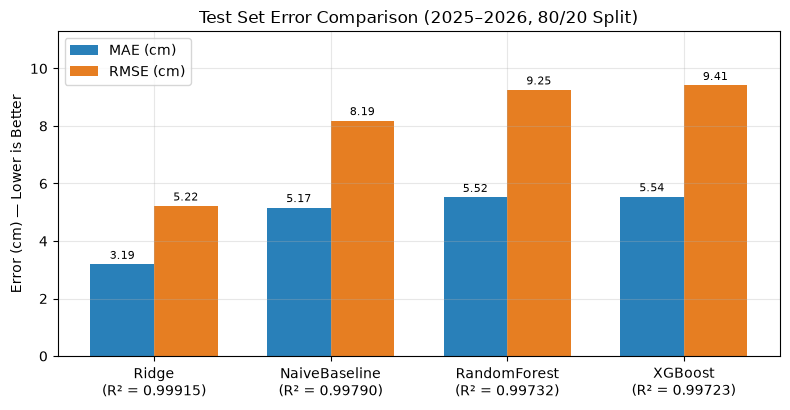

In [5]:
# Chart 1: MAE, RMSE, and R2 comparison across all 4 models
fig_bar, ax_bar = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(summary))
w = 0.36
b1 = ax_bar.bar(x - w/2, summary['MAE_m'] * 100, width=w, label='MAE (cm)', color='#2980b9')
b2 = ax_bar.bar(x + w/2, summary['RMSE_m'] * 100, width=w, label='RMSE (cm)', color='#e67e22')

labels = [f"{m}\n(R² = {r:.5f})" for m, r in zip(summary['Model'], summary['R2'])]
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(labels)
ax_bar.set_ylabel('Error (cm) — Lower is Better')
ax_bar.set_title(f"Test Set Error Comparison ({test_df['date'].min().year}–{test_df['date'].max().year}, 80/20 Split)")
ax_bar.bar_label(b1, fmt='%.2f', padding=2, fontsize=8)
ax_bar.bar_label(b2, fmt='%.2f', padding=2, fontsize=8)
ax_bar.set_ylim(0, max(summary['RMSE_m'] * 100) * 1.2)
ax_bar.legend()
plt.tight_layout()
fig_bar.savefig(REPORTS_ML_DIR / 'model_comparison_mae.png', dpi=150)
plt.show()


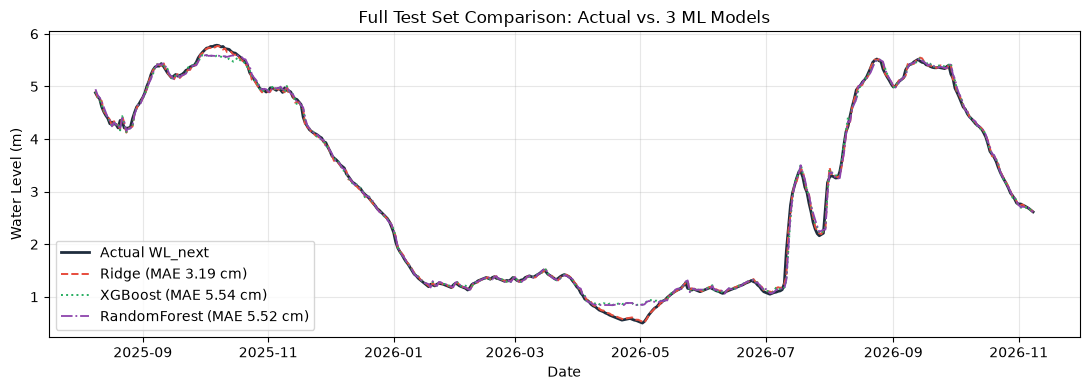

In [6]:
# Chart 2A: Full Test Set — Actual vs. 3 ML Models
mae_map = dict(zip(summary['Model'], summary['MAE_m'] * 100))

plt.figure(figsize=(11, 4))
plt.plot(test_df['date'], y_test, label='Actual WL_next', color='#1f2d3d', linewidth=2.0)
plt.plot(test_df['date'], predictions['Ridge'], label=f"Ridge (MAE {mae_map['Ridge']:.2f} cm)", color='#e74c3c', linestyle='--', linewidth=1.4)
plt.plot(test_df['date'], predictions['XGBoost'], label=f"XGBoost (MAE {mae_map['XGBoost']:.2f} cm)", color='#27ae60', linestyle=':', linewidth=1.4)
plt.plot(test_df['date'], predictions['RandomForest'], label=f"RandomForest (MAE {mae_map['RandomForest']:.2f} cm)", color='#8e44ad', linestyle='-.', linewidth=1.3)
plt.ylabel('Water Level (m)')
plt.xlabel('Date')
plt.title('Full Test Set Comparison: Actual vs. 3 ML Models')
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig(REPORTS_ML_DIR / 'actual_vs_predicted.png', dpi=150)
plt.show()


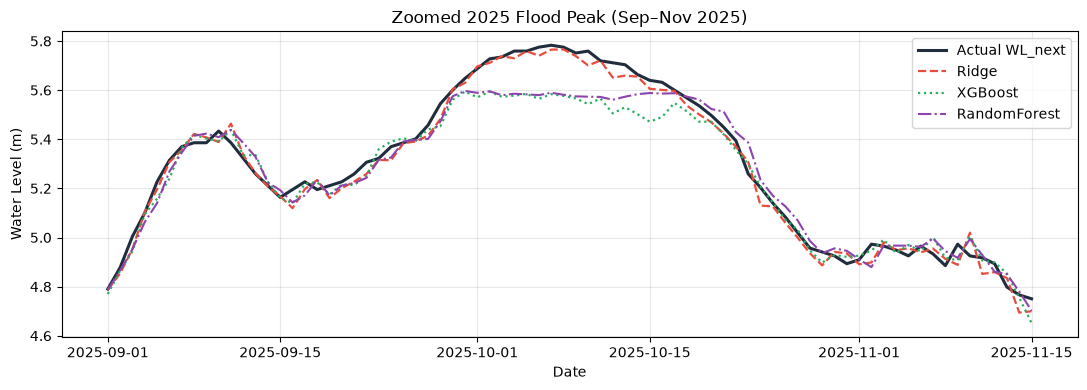

In [7]:
# Chart 2B: Zoomed 2025 Flood Peak (Sep - Nov 2025)
peak_mask = (test_df['date'] >= '2025-09-01') & (test_df['date'] <= '2025-11-15')
plt.figure(figsize=(11, 4))
plt.plot(test_df.loc[peak_mask, 'date'], y_test[peak_mask], label='Actual WL_next', color='#1f2d3d', linewidth=2.2)
plt.plot(test_df.loc[peak_mask, 'date'], predictions['Ridge'][peak_mask], label='Ridge', color='#e74c3c', linestyle='--', linewidth=1.6)
plt.plot(test_df.loc[peak_mask, 'date'], predictions['XGBoost'][peak_mask], label='XGBoost', color='#27ae60', linestyle=':', linewidth=1.6)
plt.plot(test_df.loc[peak_mask, 'date'], predictions['RandomForest'][peak_mask], label='RandomForest', color='#8e44ad', linestyle='-.', linewidth=1.5)
plt.ylabel('Water Level (m)')
plt.xlabel('Date')
plt.title('Zoomed 2025 Flood Peak (Sep–Nov 2025)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(REPORTS_ML_DIR / 'actual_vs_predicted_flood_zoom.png', dpi=150)
plt.show()


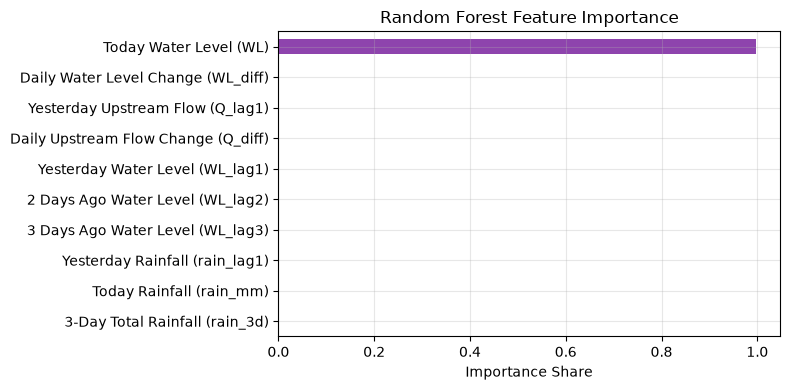

In [8]:
# Chart 3A: Random Forest Feature Importance
PRETTY_LABELS = {
    'WL': 'Today Water Level (WL)',
    'WL_lag1': 'Yesterday Water Level (WL_lag1)',
    'WL_lag2': '2 Days Ago Water Level (WL_lag2)',
    'WL_lag3': '3 Days Ago Water Level (WL_lag3)',
    'WL_diff': 'Daily Water Level Change (WL_diff)',
    'upstream_discharge_lag1': 'Yesterday Upstream Flow (Q_lag1)',
    'upstream_discharge_diff': 'Daily Upstream Flow Change (Q_diff)',
    'rain_mm': 'Today Rainfall (rain_mm)',
    'rain_lag1': 'Yesterday Rainfall (rain_lag1)',
    'rain_3d': '3-Day Total Rainfall (rain_3d)',
}
pretty_idx = [PRETTY_LABELS[c] for c in FEATURE_COLS]

plt.figure(figsize=(8, 4))
pd.Series(models['RandomForest'].feature_importances_, index=pretty_idx).sort_values().plot(kind='barh', color='#8e44ad')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Share')
plt.tight_layout()
plt.savefig(REPORTS_ML_DIR / 'feature_importance_rf.png', dpi=150)
plt.show()


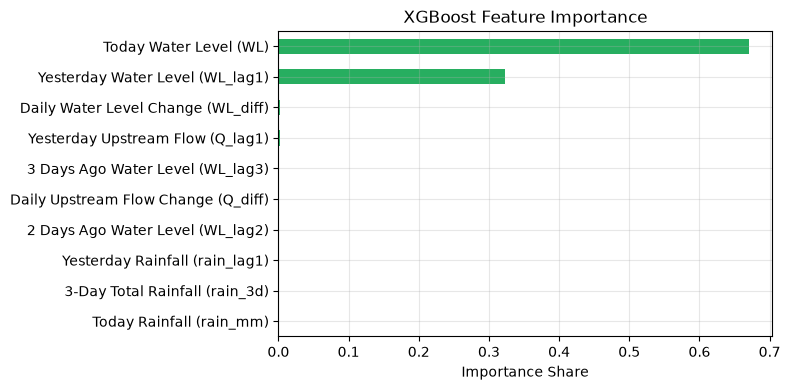

In [9]:
# Chart 3B: XGBoost Feature Importance
plt.figure(figsize=(8, 4))
pd.Series(models['XGBoost'].feature_importances_, index=pretty_idx).sort_values().plot(kind='barh', color='#27ae60')
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance Share')
plt.tight_layout()
plt.savefig(REPORTS_ML_DIR / 'feature_importance_xgb.png', dpi=150)
plt.show()


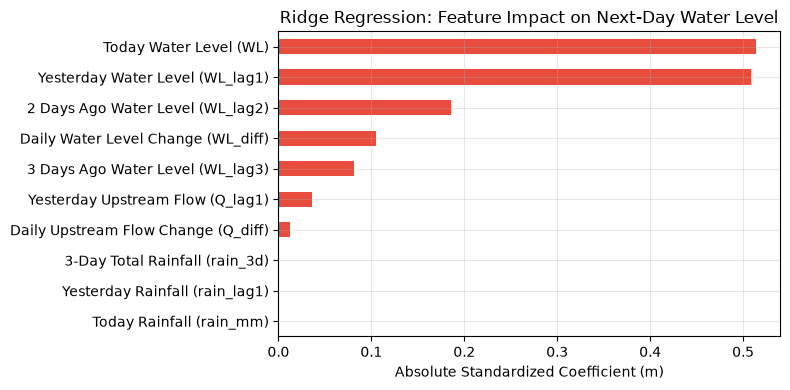

In [10]:
# Chart 3C: Ridge Standardized Coefficients on Next-Day Water Level (WL_next)
X_scaled = StandardScaler().fit_transform(X_train)
ridge_chg = Ridge(alpha=1.0).fit(X_scaled, y_train)
ridge_imp = pd.Series(np.abs(ridge_chg.coef_), index=pretty_idx).sort_values()

plt.figure(figsize=(8, 4))
ridge_imp.plot(kind='barh', color='#e74c3c')
plt.title("Ridge Regression: Feature Impact on Next-Day Water Level")
plt.xlabel('Absolute Standardized Coefficient (m)')
plt.tight_layout()
plt.savefig(REPORTS_ML_DIR / 'feature_importance.png', dpi=150)
plt.show()
